# 4주차 · 불량 후보 분류하기

**이번 실습:** 얕은 트리의 분기 조건을 그림으로 읽고, 랜덤 포레스트로 불량 후보를 분류해 놓친 불량을 셉니다.  
**권장 시간:** 50분  
**준비:** 3주차의 입력·정답·학습/시험 분리

이 파일 하나를 위에서부터 순서대로 실행합니다. 주차 안의 이론 차시마다 별도 코드를 실행할 필요는 없습니다. 오른쪽 위 커널은 **Python (semi-ai)**로 고릅니다. `#` 뒤의 한국어 주석을 한 줄씩 읽고 실행해 주세요. 데이터는 교육용 합성 자료입니다.

## 0. 실습 폴더 준비

VS Code와 Colab 어디서 열어도 `data` 폴더를 찾도록 실습 폴더 위치를 정합니다. Colab에서는 처음 한 번 실습 자료를 내려받습니다.

In [ ]:
import sys, subprocess  # 실행 환경 확인과 명령 실행 도구입니다.
from pathlib import Path  # 파일 위치 도구입니다.
if "google.colab" in sys.modules:  # Colab에서 실행 중이라면
    folder = Path("/content/semiconductor_ai_beginner")  # 실습 자료를 둘 위치입니다.
    if not folder.exists():  # 아직 내려받지 않았다면
        subprocess.run(["git", "clone", "-q", "https://github.com/SeokJH-TAs/semiconductor_ai_beginner.git", str(folder)], check=True)  # 실습 자료 전체를 내려받습니다.
else:  # VS Code 등 내 컴퓨터에서 실행 중이라면
    folder = Path.cwd()  # 현재 폴더입니다.
    if folder.name == "notebooks":  # 노트북 폴더 안이라면
        folder = folder.parent  # 실습 전체 폴더로 올라갑니다.
print(folder)  # 실습 폴더 위치를 확인합니다.

## 1. 정답 누출 없이 데이터 나누기

공정 중 불량 위험을 미리 분류하는 예제입니다. 정답을 만드는 데 사용된 사후 두께는 입력에서 제외합니다. 단순한 로지스틱 모델과 숲은 표현할 수 있는 모양이 다릅니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [1]:
from pathlib import Path  # 폴더와 파일의 위치를 다루는 도구를 꺼냅니다.
import pandas as pd  # 표를 읽는 pandas 도구를 pd라는 짧은 이름으로 부릅니다.
data = pd.read_csv(folder / "data" / "process.csv")  # data 폴더의 표를 읽어 data에 담습니다.
print(data.head())  # 표의 첫 다섯 줄을 화면에 보여 줍니다.

from sklearn.model_selection import train_test_split  # 나누기 도구입니다.
X = data[["temperature_c", "pressure_torr", "gas_flow_sccm", "rf_power_w"]]  # 사전 공정 조건입니다.
y = data["defect"]  # 공정 후 검사 정답입니다.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)  # 불량 비율을 비슷하게 나눕니다.

  sample_id  temperature_c  pressure_torr  gas_flow_sccm  rf_power_w  \
0      W001        413.698          1.664        110.439     221.019   
1      W002        396.944          1.637        100.881     214.638   
2      W003        417.930          1.186        119.415     182.867   
3      W004        409.868          1.425        105.852     256.782   
4      W005        379.709          1.485         91.803     188.240   

   thickness_nm  defect  
0       104.018       1  
1        97.325       0  
2       107.485       1  
3       100.399       0  
4        92.937       0  


**실행 후 확인:** stratify는 정답 비율이 한쪽으로 치우치지 않도록 돕습니다.

## 2. 얕은 나무와 숲 준비하기

깊이 3은 질문 단계를 제한합니다. n_estimators=60은 트리 60개를 모은다는 뜻입니다. 시험 점수로 후보를 계속 바꾸는 실습은 하지 않습니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [2]:
from sklearn.tree import DecisionTreeClassifier  # 결정 트리 도구입니다.
from sklearn.ensemble import RandomForestClassifier  # 여러 트리를 모으는 도구입니다.
tree = DecisionTreeClassifier(max_depth=3, random_state=42)  # 깊이를 제한한 트리입니다.
forest = RandomForestClassifier(n_estimators=60, max_depth=5, random_state=42)  # 트리 60개의 숲입니다.
tree.fit(X_train, y_train)  # 학습용 표로 나무를 배웁니다.
forest.fit(X_train, y_train)  # 같은 학습 표로 숲을 배웁니다.
print(tree.score(X_test, y_test), forest.score(X_test, y_test))  # 두 정확도를 참고로 봅니다.

0.8 0.8666666666666667


**실행 후 확인:** 숲이 항상 더 좋다는 법칙은 없습니다. 정확도만으로 결론내리지 않습니다.

## 2-1. 결정 트리의 질문을 그림으로 보기

2번에서 이미 학습한 `tree`를 그대로 그립니다. 여기서 새 모델을 만들거나 시험 정답으로 다시 학습하지 않습니다. 각 네모는 **노드**, 이어지는 선은 **가지**, 질문 없이 판정을 내리는 끝 노드는 **잎**입니다.

첫 줄이 `temperature_c <= 416.62`라면 온도가 기준 이하인 기록은 왼쪽, 초과한 기록은 오른쪽으로 내려갑니다. 아래로 내려가며 질문을 반복합니다. 그림의 임계값은 읽기 위해 소수 둘째 자리로 반올림했으며 실제 판정은 모델 안의 더 정확한 값을 사용합니다.

아래 코드의 여러 줄 괄호는 한 함수를 읽기 쉽게 나눈 것입니다. `feature_names`는 입력 열 이름, `class_names`는 라벨 0·1의 표시 이름입니다. `Normal`은 정상(0), `Defect`는 불량(1)입니다.

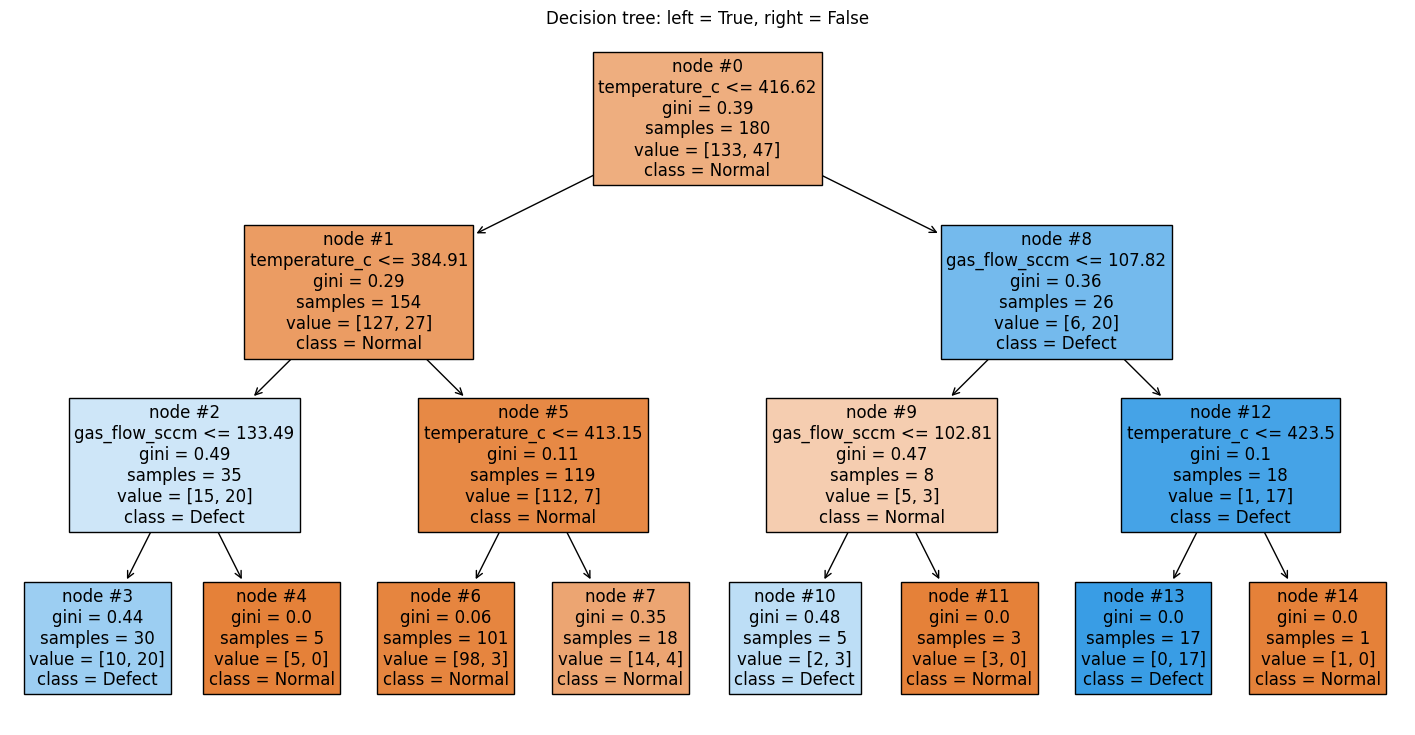

In [3]:
import matplotlib.pyplot as plt  # 그림을 그리는 도구입니다.
from sklearn.tree import plot_tree  # 학습한 트리의 질문을 그리는 도구입니다.
plt.figure(figsize=(18, 9))  # 전체 노드를 읽을 수 있게 넓은 그림을 만듭니다.
plot_tree(  # 아래 설정으로 기존 tree를 그립니다.
    tree,  # 2번에서 학습한 결정 트리입니다.
    feature_names=list(X.columns),  # 입력 열 순서대로 질문 이름을 붙입니다.
    class_names=["Normal", "Defect"],  # 정답 0과 1의 이름입니다.
    filled=True,  # 많이 포함된 클래스에 따라 노드 색을 칠합니다.
    node_ids=True,  # 경로를 따라갈 수 있도록 노드 번호를 표시합니다.
    precision=2,  # 그림에 표시할 소수 자릿수입니다.
    fontsize=12,  # 노드 안 글자 크기입니다.
)  # 그림 설정을 마칩니다.
plt.title("Decision tree: left = True, right = False")  # 가지의 뜻입니다.
plt.show()  # 전체 트리 그림을 보여 줍니다.

### 노드 안의 숫자 읽기

| 표시 | 쉬운 뜻 |
|---|---|
| `node #0` | 첫 노드의 번호입니다. 번호 자체에 품질 순위는 없습니다. |
| `temperature_c <= ...` | 온도가 이 값 이하인지 묻는 분기 조건입니다. 참은 왼쪽, 거짓은 오른쪽입니다. |
| `gini` | 정상·불량이 섞인 정도입니다. 0이면 한 클래스만 있습니다. 정확도는 아닙니다. |
| `samples` | 이 노드까지 도착한 **학습 기록** 수입니다. 시험 기록 수가 아닙니다. |
| `value = [정상, 불량]` | 수업 환경 scikit-learn 1.3의 각 클래스 학습 기록 수입니다. 다른 버전에서는 비율로 보일 수 있습니다. |
| `class` | 이 노드의 다수 클래스입니다. 최종 예측은 끝 노드까지 내려가서 정합니다. |

색의 종류는 다수 클래스, 진하기는 한쪽 클래스가 얼마나 많은지를 나타냅니다. gini는 노드 안의 섞임이며 시험 성능과 구별합니다. 이 예제는 가중치 없이 학습했습니다.

모델은 학습 자료에서 여러 특징과 기준값 후보를 비교하여, 나뉜 자식 노드의 **샘플 수를 고려한 gini 평균**을 작게 하는 분기를 찾습니다. 질문 순서는 이 합성 자료에서 학습한 결과이며 인과관계나 검증된 공정 관리 기준을 뜻하지 않습니다.

**직접 확인:** 루트의 `samples`와 `value` 합이 학습 행 수 180과 같은지 보세요. 잎 노드에서는 왜 더 이상 조건문이 표시되지 않나요? 깊이를 3으로 제한했기 때문에 정상·불량이 섞여 있어도 멈춘 잎이 있을 수 있습니다.

[plot_tree 공식 문서 (수업 환경 1.3)](https://scikit-learn.org/1.3/modules/generated/sklearn.tree.plot_tree.html)

## 2-2. 시험 기록 한 개의 실제 경로 따라가기

그림을 눈으로 읽은 뒤, 시험 기록 하나가 지나간 노드 번호를 출력합니다. `decision_path`는 통과한 노드들, `apply`는 마지막 잎의 번호입니다. `toarray()`는 노드 통과 표시를 보통 숫자 표로 바꿉니다. 1인 위치만 `flatnonzero`로 꺼냅니다.

이 구역은 **결정 트리 tree**의 판정입니다. 뒤의 3번 혼동행렬은 **랜덤 포레스트 forest**의 판정이므로 두 모델의 결과를 구별합니다.

In [4]:
import numpy as np  # 1인 위치의 번호를 꺼내는 도구입니다.
one_record = X_test.iloc[[0]]  # 시험 표의 첫 행을 한 행짜리 표로 꺼냅니다.
print(one_record)  # 이 기록의 실제 온도·압력·유량·전력을 봅니다.
path = tree.decision_path(one_record)  # 이 기록이 지나간 노드들을 표시합니다.
node_numbers = np.flatnonzero(path.toarray()[0])  # 1로 표시된 노드 번호만 꺼냅니다.
print("통과한 노드:", node_numbers)  # 그림의 node 번호와 맞춰 봅니다.
print("도착한 잎:", tree.apply(one_record))  # 마지막으로 도착한 끝 노드입니다.
print("트리 예측:", tree.predict(one_record))  # 이 잎의 다수 클래스입니다.
print("실제 정답:", y_test.iloc[0])  # 비교할 시험 정답입니다.

     temperature_c  pressure_torr  gas_flow_sccm  rf_power_w
161        420.801          1.735        130.044     228.142
통과한 노드: [ 0  8 12 13]
도착한 잎: [13]
트리 예측: [1]
실제 정답: 1


## 3. 숲의 네 칸 채점표 읽기

[[TN,FP],[FN,TP]] 순서입니다. FN은 실제 불량인데 정상으로 놓친 수입니다. 이 수가 공정 검사에서 어떤 비용을 만드는지 생각해 봅니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [5]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score  # 분류 채점 도구입니다.
predicted = forest.predict(X_test)  # 0 또는 1 판정입니다.
probability = forest.predict_proba(X_test)[:, 1]  # 모든 행에서 두 번째 열, 불량 확률을 꺼냅니다.
print(confusion_matrix(y_test, predicted, labels=[0, 1]))  # 실제 행, 예측 열의 네 칸 표입니다.
print(precision_score(y_test, predicted, zero_division=0))  # 불량 후보 중 실제 불량의 비율입니다.
print(recall_score(y_test, predicted))  # 실제 불량 중 찾은 비율입니다.
print(roc_auc_score(y_test, probability))  # 임계값 전반의 순위 구분 성능입니다.

[[41  4]
 [ 4 11]]
0.7333333333333333
0.7333333333333333
0.9170370370370371


**실행 후 확인:** 정밀도·재현율은 0~1입니다. AUC는 판정 라벨이 아니라 확률로 계산합니다.

## 직접 바꾸기

3번 구역 뒤에 아래 셀을 실행합니다. 같은 확률에 기준만 낮춰 후보를 더 많이 고르면 놓친 불량 수가 어떻게 달라지는지 봅니다. 새 모델을 학습하는 것이 아닙니다.

In [6]:
low_threshold = 0.3  # 불량 후보로 보낼 확률 기준을 낮춥니다.
more_candidates = (probability >= low_threshold).astype(int)  # 기준 이상을 1로 표시합니다.
print(confusion_matrix(y_test, more_candidates, labels=[0, 1]))  # 실제 행·예측 열 순서로 다시 셉니다.
print(recall_score(y_test, more_candidates))  # 실제 불량 중 찾은 비율을 비교합니다.

[[34 11]
 [ 4 11]]
0.7333333333333333


**확인:** 기준을 낮추면 후보 수가 줄지는 않습니다. 재현율은 같거나 높아질 수 있지만 정상도 더 많이 후보로 보낼 수 있습니다.

## 선택 · 트리의 질문 읽기

조건문이 어떤 모양인지 직접 보고 싶을 때만 아래 구역을 실행합니다.

### 선택. 트리의 질문 읽기

읽을 수 있는 작은 나무에서 분기 기준을 살펴봅니다. 트리에서 쓴 특징 이름과 X 열 순서가 같아야 합니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [7]:
from sklearn.tree import export_text  # 나무의 질문을 글로 보여 주는 도구입니다.
rules = export_text(tree, feature_names=list(X.columns))  # 실제 입력 열 이름으로 질문을 적습니다.
print(rules)  # 조건과 마지막 판정을 봅니다.

|--- temperature_c <= 416.62
|   |--- temperature_c <= 384.91
|   |   |--- gas_flow_sccm <= 133.49
|   |   |   |--- class: 1
|   |   |--- gas_flow_sccm >  133.49
|   |   |   |--- class: 0
|   |--- temperature_c >  384.91
|   |   |--- temperature_c <= 413.15
|   |   |   |--- class: 0
|   |   |--- temperature_c >  413.15
|   |   |   |--- class: 0
|--- temperature_c >  416.62
|   |--- gas_flow_sccm <= 107.82
|   |   |--- gas_flow_sccm <= 102.81
|   |   |   |--- class: 1
|   |   |--- gas_flow_sccm >  102.81
|   |   |   |--- class: 0
|   |--- gas_flow_sccm >  107.82
|   |   |--- temperature_c <= 423.50
|   |   |   |--- class: 1
|   |   |--- temperature_c >  423.50
|   |   |   |--- class: 0



**실행 후 확인:** 온도나 유량 등의 기준값을 순서대로 묻는 글이 나옵니다.